# Étape 7 – Visualisations finales et interprétation

Ce notebook assemble les figures destinées au **rapport** à partir des résultats des étapes 5 et 6 (aucun modèle n'est ré-entraîné ici). Chaque figure répond à **une question** et s'accompagne d'une lecture ; les limites sont rappelées en fin de document.

*Nuages de mots : volontairement non produits.* Avec des titres de ≈ 7 mots informatifs et un vocabulaire sans mot dominant (le lemme le plus fréquent figure dans 3,4 % des titres), un nuage n'apporterait rien de plus que les barres de fréquence et de log-odds de l'étape 4, tout en étant moins lisible.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)
MEDIA_ORDER = ["Le Progrès", "Lyon Capitale", "LyonMag", "BFM Lyon"]
MEDIA_COLORS = dict(zip(MEDIA_ORDER, sns.color_palette("deep")[:4]))

from src.preprocessing.text_cleaning import add_token_columns

corpus = pd.read_parquet(ROOT / "data" / "processed" / "corpus.parquet")
topics = pd.read_parquet(ROOT / "data" / "processed" / "article_topics.parquet")[["article_id", "km", "km_label"]]
df = corpus[corpus.in_analysis & corpus.media_name.isin(MEDIA_ORDER[:3])].merge(topics, on="article_id", how="inner").reset_index(drop=True)
ev = pd.read_csv(TAB / "06_evenements_emergents.csv", parse_dates=["semaine"])
share = pd.read_csv(TAB / "06_themes_parts_hebdo.csv", index_col=0)
trend = pd.read_csv(TAB / "06_themes_tendances.csv")
print(f"{len(df):,} titres (3 médias principaux), {len(ev)} termes émergents annotés/détectés, {share.shape[1]} thèmes")

4,851 titres (3 médias principaux), 87 termes émergents annotés/détectés, 14 thèmes


## Figure 1 – Quels thèmes dominent la presse lyonnaise, et comment évoluent-ils ?
Part de chaque thème K-Means dans les titres de chaque semaine (médias pondérés à parts fixes, voir étape 6). Les lignes sont triées par part moyenne ; l'étiquette « ↑ » / « ↓ » indique une tendance significative (ρ de Spearman ≥ 0,6 en valeur absolue, p < 0,05).

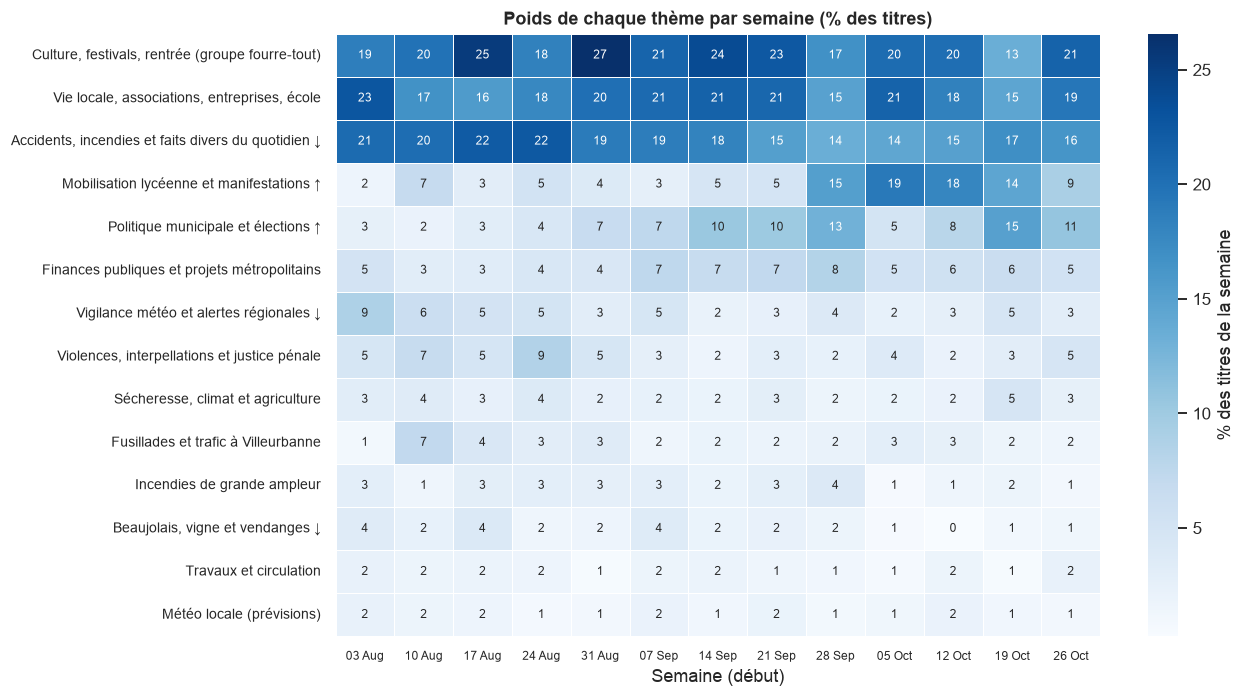

In [2]:
tr = trend.set_index("cluster")
H = share.copy(); H.columns = [int(c.split(" ")[0]) for c in H.columns]
order = H.mean().sort_values(ascending=False).index
arrow = {"en hausse": " ↑", "en baisse": " ↓"}
ylabels = [f"{tr.loc[k, 'thème']}{arrow.get(tr.loc[k, 'tendance'], '')}" for k in order]
fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(H[order].T, cmap="Blues", annot=True, fmt=".0f", annot_kws={"size": 8}, cbar_kws={"label": "% des titres de la semaine"}, linewidths=0.4, linecolor="white", ax=ax)
ax.set_yticklabels(ylabels, rotation=0, fontsize=9); ax.set(title="Poids de chaque thème par semaine (% des titres)", xlabel="Semaine (début)", ylabel="")
ax.set_xticklabels(list(H.index), rotation=0, fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "07_fig1_themes_par_semaine.png", bbox_inches="tight"); plt.show()

**Lecture.**
- Trois grands registres occupent en moyenne **57 % des titres** : culture, festivals et rentrée (20,7 %), vie locale (18,8 %), faits divers du quotidien (17,9 %). Ils forment le « fond » de la presse locale, et deux des trois sont des groupes larges, partiellement fourre-tout.
- Le thème **mobilisation lycéenne** passe de 2-7 % des titres en août-septembre à **15 % (28 septembre), 19 % (5 octobre) et 18 % (12 octobre)**, puis redescend à 14 % puis 9 % : un titre sur cinq à son maximum, puis un retrait rapide.
- **Politique municipale et élections** monte de 2-4 % en août à 10-13 % de la mi-septembre à fin septembre, retombe à 5 % (5 octobre) et remonte à 15 % (19 octobre).
- Deux baisses sont à lire avec prudence : **faits divers du quotidien** (21-22 % en août, 14-19 % ensuite) et **vigilance météo** (9 % le 3 août, 2-5 % en octobre : la canicule de l'été). Les parts sont en somme 100 % : quand mobilisation et politique grossissent, les autres reculent mécaniquement.

## Figure 2 – Quels événements ont émergé, et quand ?
Chaque bulle est un **événement** (regroupement des termes émergents annotés à la main, étape 6) placé à sa semaine de pic ; la taille est le nombre maximal de titres la semaine du pic, la couleur la trajectoire du terme principal.

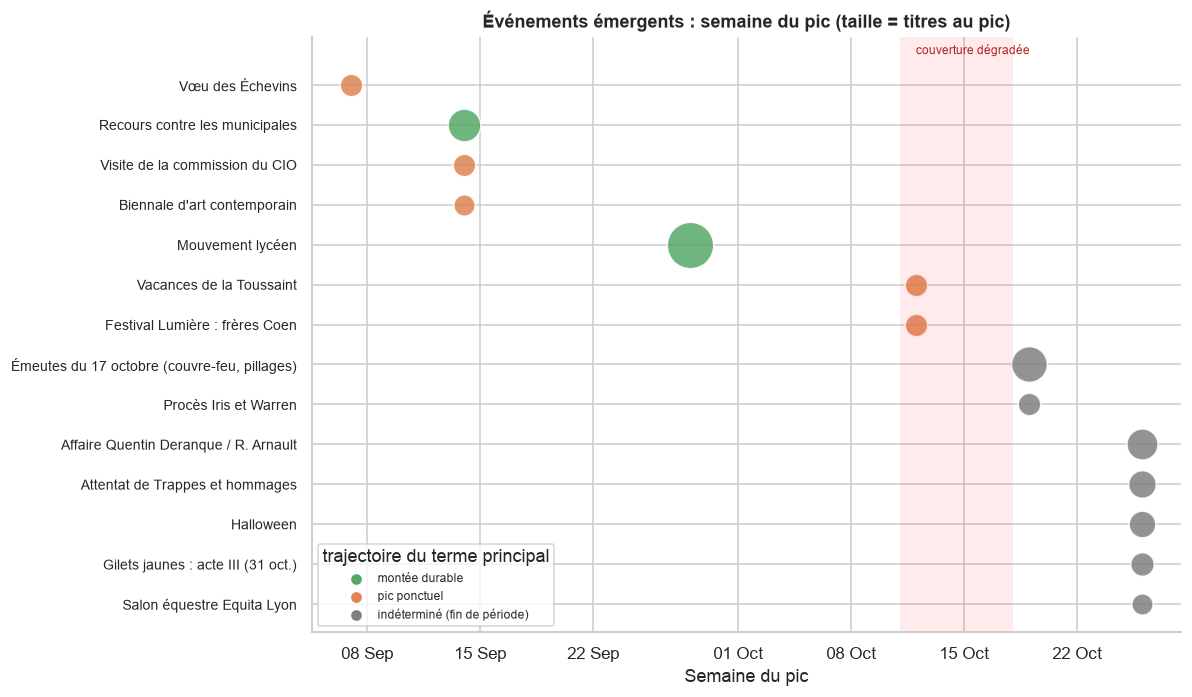

,événement,semaine,titres,z,termes,trajectoire,exemple
12,Vœu des Échevins,07 Sep,8,9.5,1,pic ponctuel,Alain Mérieux va remettre l'écu lors du renouvellement du Vœu des ...
8,Recours contre les municipales,14 Sep,19,12.3,2,montée durable,"Municipales : le recours de Jean-Michel Aulas n'a pas convaincu, l..."
11,Visite de la commission du CIO,14 Sep,8,8.9,1,pic ponctuel,« Nous sommes une organisation extrêmement démocratique » : le gr...
2,Biennale d'art contemporain,14 Sep,7,8.0,1,pic ponctuel,Lyon : une nouvelle exposition d'art contemporain à découvrir dans...
6,Mouvement lycéen,28 Sep,40,24.2,9,montée durable,"A Ecully, des lycéens en direct avec la station orbitale : le comp..."
10,Vacances de la Toussaint,12 Oct,8,9.2,1,pic ponctuel,"« Deux cambriolages en sept ans, ça fait beaucoup » : un couple se..."
3,Festival Lumière : frères Coen,12 Oct,8,9.1,1,pic ponctuel,Festival Lumière : pourquoi la venue des frères Coen à Lyon ravive...
13,"Émeutes du 17 octobre (couvre-feu, pillages)",19 Oct,23,24.4,8,indéterminé (fin de période),Émeutes du 17 octobre à Lyon: un couvre-feu instauré en Presqu'île...
7,Procès Iris et Warren,19 Oct,8,9.3,1,indéterminé (fin de période),"Mort d'Iris et Warren : à l'heure du procès, retour sur les lieux ..."
0,Affaire Quentin Deranque / R. Arnault,26 Oct,17,20.5,2,indéterminé (fin de période),L'ex-candidat RN Alexandre Dupalais appelle à l'interdiction d'une...


In [3]:
def family(label):
    l = label
    if l.startswith("Émeutes") or "Acte II »" in l or l.startswith("« Acte II »"): return "Émeutes du 17 octobre (couvre-feu, pillages)"
    if l.startswith("« Acte III"): return "Gilets jaunes : acte III (31 oct.)"
    if l.startswith("Mouvement lycéen") or l.startswith("Manifestations lycéennes"): return "Mouvement lycéen"
    if l.startswith("Affaire Quentin"): return "Affaire Quentin Deranque / R. Arnault"
    if l.startswith("Recours"): return "Recours contre les municipales"
    return l.split(" (")[0]
a = ev[ev["événement (annotation manuelle)"].notna()].copy()
a["événement"] = a["événement (annotation manuelle)"].map(family)
fam = (a.sort_values("z", ascending=False).groupby("événement")
        .agg(semaine=("semaine", "first"), titres=("titres au pic", "max"), z=("z", "max"), termes=("terme", "nunique"), trajectoire=("trajectoire", "first"), exemple=("exemple de titre", "first"))
        .reset_index().sort_values(["semaine", "z"], ascending=[True, False]))
fam.to_csv(TAB / "07_tableau_sujets_emergents.csv", index=False)
traj_col = {"montée durable": sns.color_palette()[2], "pic ponctuel": sns.color_palette()[1], "indéterminé (fin de période)": "grey"}
fig, ax = plt.subplots(figsize=(11, 6.5))
y = {e: i for i, e in enumerate(fam["événement"][::-1])}
for _, r in fam.iterrows():
    ax.scatter(r.semaine, y[r["événement"]], s=40 + 22 * r.titres, color=traj_col[r.trajectoire], alpha=0.85, edgecolor="white")
ax.set_yticks(list(y.values())); ax.set_yticklabels(list(y.keys()), fontsize=9)
ax.axvspan(pd.Timestamp("2026-10-12") - pd.Timedelta(days=1), pd.Timestamp("2026-10-12") + pd.Timedelta(days=6), color="red", alpha=0.08, lw=0)
ax.text(pd.Timestamp("2026-10-12"), len(y) - 0.3, "couverture dégradée", color="firebrick", fontsize=8, va="bottom")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.set(title="Événements émergents : semaine du pic (taille = titres au pic)", xlabel="Semaine du pic", ylim=(-0.7, len(y) + 0.2))
for k, c in traj_col.items(): ax.scatter([], [], color=c, label=k)
ax.legend(title="trajectoire du terme principal", loc="lower left", fontsize=8); plt.tight_layout(); fig.savefig(FIG / "07_fig2_evenements_emergents.png", bbox_inches="tight"); plt.show()
pd.set_option("display.max_colwidth", 70); display(fam.assign(semaine=fam.semaine.dt.strftime("%d %b"), z=fam.z.round(1)))

**Lecture.**
- On distingue **trois vagues** : (1) mi-septembre, une actualité institutionnelle (recours contre les municipales, visite du CIO pour les JO 2030, Biennale d'art contemporain) ; (2) de fin septembre à mi-octobre, le **mouvement lycéen**, de loin le plus gros événement (40 titres au pic, 9 termes détectés) ; (3) fin octobre, une série de chocs : **émeutes du 17 octobre** (couvre-feu, pillages), **affaire Quentin Deranque**, attentat de Trappes, « acte III » des Gilets jaunes.
- Seuls deux événements sont classés en *montée durable* (le recours contre les municipales et le mouvement lycéen). Sept événements sur 14 sont « indéterminés », non parce qu'ils sont ponctuels, mais parce que leur pic tombe dans les deux dernières semaines : **on ne peut pas savoir s'ils durent**.
- Les événements de la semaine du 12 octobre (Toussaint, festival Lumière) sont à lire avec réserve (couverture dégradée du Progrès).
- Tous les événements détectés sont des événements **datés et collectifs** (manifestations, procès, festivals). Un changement de fond lent (par exemple un thème qui grossit sur dix semaines) est moins bien capté par un score de rupture.

## Figure 3 – Les médias parlent-ils des mêmes thèmes ?
Pour chaque média, la part de ses titres dans chaque thème, comparée à la part de l'ensemble du corpus : une valeur de **+1** signifie 2 fois plus de titres que la moyenne (log₂ du rapport), **−1** deux fois moins. Les chiffres affichés sont les pourcentages réels du média.

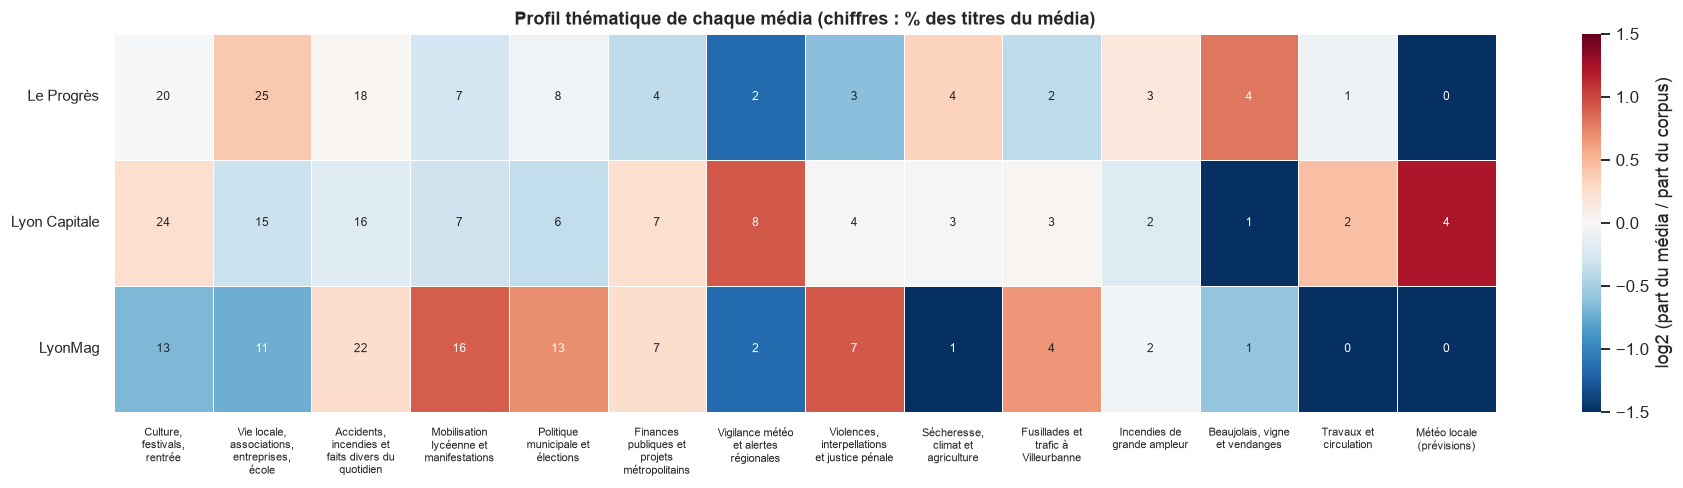

Test du χ² d'indépendance média × thème : χ² = 540, ddl = 26, p = 1.5e-97  (V de Cramér = 0.24)


In [4]:
M3 = ["Le Progrès", "Lyon Capitale", "LyonMag"]
ct = pd.crosstab(df.media_name, df.km, normalize="index").reindex(M3) * 100
overall = df.km.value_counts(normalize=True).sort_index() * 100
lr = np.log2(ct / overall)
lab = df.drop_duplicates("km").set_index("km")["km_label"].sort_index()
order = overall.sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(17, 4.6))
sns.heatmap(lr[order], cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5, annot=ct[order].round(0), fmt=".0f", annot_kws={"size": 8}, cbar_kws={"label": "log2 (part du média / part du corpus)"}, linewidths=0.4, linecolor="white", ax=ax)
import textwrap
ax.set_xticklabels(["\n".join(textwrap.wrap(lab[k].replace(" (groupe fourre-tout)", ""), 17)) for k in order], rotation=0, ha="center", fontsize=7.5)
ax.set_yticklabels(M3, rotation=0, fontsize=10); ax.set(title="Profil thématique de chaque média (chiffres : % des titres du média)", xlabel="", ylabel="")
plt.tight_layout(); fig.savefig(FIG / "07_fig3_profil_thematique_medias.png", bbox_inches="tight"); plt.show()
from scipy.stats import chi2_contingency
chi2, pval, dof, _ = chi2_contingency(pd.crosstab(df.media_name, df.km))
print(f"Test du χ² d'indépendance média × thème : χ² = {chi2:.0f}, ddl = {dof}, p = {pval:.1e}  (V de Cramér = {np.sqrt(chi2 / (len(df) * 2)):.2f})")

**Lecture.**
- Les médias n'ont pas le même profil thématique : le test d'indépendance média × thème est très significatif (χ² = 540, 26 ddl, p < 10⁻⁹⁰), avec une association **modérée** (V de Cramér = 0,24) : les médias se recoupent largement mais gardent des spécialités.
- **Le Progrès** surreprésente la **vie locale** (25 % de ses titres contre 15 % pour Lyon Capitale et 11 % pour LyonMag) et le Beaujolais (4 %) ; il traite très peu la vigilance météo (2 %).
- **Lyon Capitale** surreprésente la **vigilance météo** (8 %) et la météo locale (4 %) et la culture (24 %) ; elle est quasi absente du Beaujolais (1 %).
- **LyonMag** surreprésente la **mobilisation lycéenne** (16 % contre 7 % ailleurs), la **politique municipale** (13 %), les violences (7 %) et les fusillades de Villeurbanne ; il traite peu la culture (13 %) et la vie locale (11 %).
- Ce résultat **converge avec l'analyse de vocabulaire de l'étape 4** (Le Progrès : vie locale ; Lyon Capitale : alertes régionales ; LyonMag : politique et sécurité), obtenue par une méthode différente : c'est un indice de robustesse.

## Figure 4 – Qui parle le premier ?
Pour quelques événements, date du **premier titre** de chaque média contenant le terme. Précaution : pour Le Progrès, la date est la date de publication lue dans l'URL ; pour Lyon Capitale et LyonMag, c'est la date de détection par GDELT (en pratique le jour même ou le lendemain). Les écarts d'un jour ne sont donc pas interprétables.

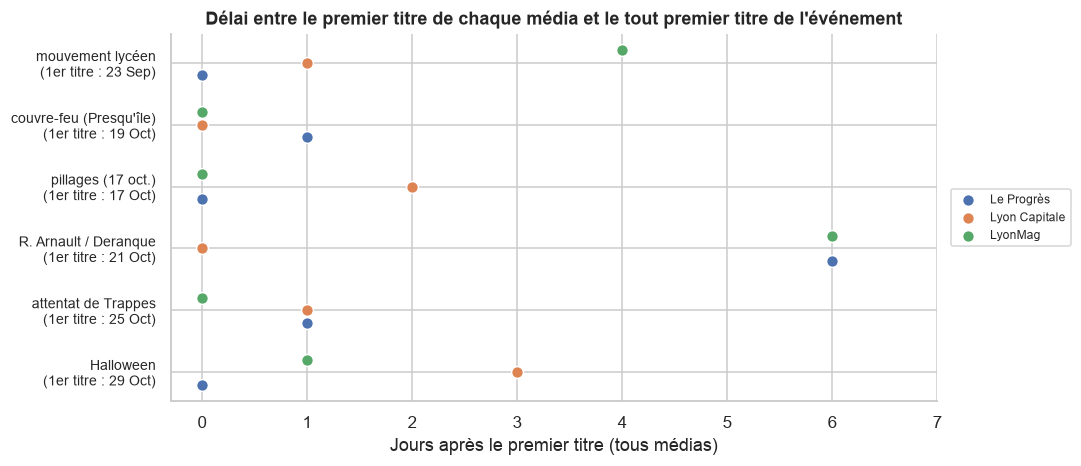

média,Le Progrès,Lyon Capitale,LyonMag
événement,,,
mouvement lycéen,23 Sep,24 Sep,27 Sep
couvre-feu (Presqu'île),20 Oct,19 Oct,19 Oct
pillages (17 oct.),17 Oct,19 Oct,17 Oct
R. Arnault / Deranque,27 Oct,21 Oct,27 Oct
attentat de Trappes,26 Oct,26 Oct,25 Oct
Halloween,29 Oct,01 Nov,30 Oct


In [5]:
dfa = add_token_columns(df)
# terme de recherche -> libellé ; la fenêtre démarre le lundi précédant la semaine de pic du terme (étape 6) pour exclure les usages sans rapport avec l'événement
probe = {"lycéen": "mouvement lycéen", "couvre-feu": "couvre-feu (Presqu'île)", "pillage": "pillages (17 oct.)", "arnault": "R. Arnault / Deranque", "trappe": "attentat de Trappes", "halloween": "Halloween"}
peak = ev.groupby("terme")["semaine"].first()
peak_for = {"lycéen": peak["lycéen"], "couvre-feu": peak["couvre-feu"], "pillage": peak["pillage"], "arnault": peak["raphaël arnault"], "trappe": peak["trappe"], "halloween": peak["halloween"]}
rows = []
for term, name in probe.items():
    start = peak_for[term] - pd.Timedelta(days=7)
    has = (dfa.tokens_lemma.map(lambda t: term in t) | dfa.title_clean.str.lower().str.contains(term, regex=False)) & (dfa.date >= start)
    for m in M3:
        sub = dfa[has & (dfa.media_name == m)]
        if len(sub): rows.append({"événement": name, "média": m, "premier titre": sub.date.min(), "titres": len(sub)})
first = pd.DataFrame(rows)
first["jours après le 1er titre"] = (first["premier titre"] - first.groupby("événement")["premier titre"].transform("min")).dt.days
ev_order = list(probe.values())[::-1]
fig, ax = plt.subplots(figsize=(10, 4.4))
for m, off in zip(M3, (-0.2, 0, 0.2)):
    s_ = first[first.média == m]
    ax.scatter(s_["jours après le 1er titre"], [ev_order.index(e) + off for e in s_["événement"]], color=MEDIA_COLORS[m], s=60, label=m, edgecolor="white", zorder=3)
ax.set_yticks(range(len(ev_order))); ax.set_yticklabels([f"{e}\n(1er titre : {first[first.événement == e]['premier titre'].min():%d %b})" for e in ev_order], fontsize=9)
ax.set(title="Délai entre le premier titre de chaque média et le tout premier titre de l'événement", xlabel="Jours après le premier titre (tous médias)", xticks=range(0, 8))
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.tight_layout()
fig.savefig(FIG / "07_fig4_premier_titre_par_media.png", bbox_inches="tight"); plt.show()
first.pivot(index="événement", columns="média", values="premier titre").reindex(list(probe.values())).apply(lambda c: c.dt.strftime("%d %b"))

**Lecture.** Sur ces six événements, les trois médias publient leurs premiers titres à **0 à 4 jours** d'écart (couvre-feu : 19-20 octobre ; pillages : 17-19 octobre ; Trappes : 25-26 octobre ; Halloween : 29 octobre – 1er novembre ; mouvement lycéen : 23-27 septembre), sauf l'affaire Deranque (**6 jours** : Lyon Capitale le 21 octobre, les deux autres le 27). **Aucun média n'est systématiquement en avance** : Le Progrès est le premier sur le mouvement lycéen, LyonMag sur Trappes et Lyon Capitale sur l'affaire Deranque (21 octobre, à vérifier : la mention « Arnault » du 21 octobre peut précéder l'audition). Les écarts sont de l'ordre de la précision des dates (détection GDELT), on ne peut donc pas parler de « réactivité » d'un média.

## Tableau – Sujets émergents (pour le rapport)
Version synthétique du tableau de l'étape 6 : un événement par ligne (`outputs/tables/07_tableau_sujets_emergents.csv`). Voir la figure 2 pour la lecture visuelle.

In [6]:
t = fam.assign(semaine=fam.semaine.dt.strftime("%d %b"), z=fam.z.round(1)).rename(columns={"titres": "titres au pic", "termes": "termes détectés"})
t[["semaine", "événement", "termes détectés", "titres au pic", "z", "trajectoire"]].reset_index(drop=True)

,semaine,événement,termes détectés,titres au pic,z,trajectoire
0,07 Sep,Vœu des Échevins,1,8,9.5,pic ponctuel
1,14 Sep,Recours contre les municipales,2,19,12.3,montée durable
2,14 Sep,Visite de la commission du CIO,1,8,8.9,pic ponctuel
3,14 Sep,Biennale d'art contemporain,1,7,8.0,pic ponctuel
4,28 Sep,Mouvement lycéen,9,40,24.2,montée durable
5,12 Oct,Vacances de la Toussaint,1,8,9.2,pic ponctuel
6,12 Oct,Festival Lumière : frères Coen,1,8,9.1,pic ponctuel
7,19 Oct,"Émeutes du 17 octobre (couvre-feu, pillages)",8,23,24.4,indéterminé (fin de période)
8,19 Oct,Procès Iris et Warren,1,8,9.3,indéterminé (fin de période)
9,26 Oct,Affaire Quentin Deranque / R. Arnault,2,17,20.5,indéterminé (fin de période)


## Limites et validité

- **Une seule saison, 13 semaines** : on ne distingue pas un déclin éditorial d'un cycle saisonnier (canicule, vendanges), ni une tendance longue d'un événement ponctuel. La moitié des événements détectés ont un pic en fin de période et leur durabilité est indéterminée.
- **Source** : GDELT n'indexe qu'une partie des articles ; trois médias seulement exploitables (Le Progrès 45 % des titres analysés, Lyon Capitale 38 %, LyonMag 17 %) ; Rue89Lyon, Tribune de Lyon et Actu Lyon sont absents. Les conclusions valent pour **ces médias**, pas pour « la presse lyonnaise ». Le Progrès a un trou de couverture les 11-13 octobre.
- **Titres seulement** : pas de texte intégral (récupérable seulement dans le respect des conditions d'accès et des droits d'auteur, ce que nous n'avons pas fait). Les titres sont courts (≈ 7 mots informatifs).
- **Thèmes (K-Means)** : instables d'une graine à l'autre (ARI ≈ 0,25), non validés par une vérité terrain, avec plusieurs groupes fourre-tout. Les conclusions au niveau des thèmes sont qualitatives ; celles au niveau des mots et expressions sont mieux étayées (31 des 32 premiers termes émergents correspondent à un événement identifié à la lecture).
- **Évaluation** : l'annotation des événements est la nôtre, sans second lecteur ; le z d'émergence est un indice de classement et non une p-valeur ; ≈ 12 500 tests ont été menés.
- **Filtre lyonnais** : heuristique (précision correcte, rappel limité pour les médias lyonnais), non évaluée par un échantillon annoté.
- **Dates** : date de publication lue dans l'URL pour Le Progrès, date de détection GDELT pour les autres ; des écarts de un à deux jours ne sont pas interprétables.
- **Pistes** : embeddings de phrases ou BERTopic (non testés : PyTorch et un modèle à télécharger) pour mieux regrouper les titres ; plus de médias et une période plus longue ; récupération autorisée du texte des articles ; annotation d'un échantillon par deux lecteurs.